In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [75]:
df = pd.read_csv('diabetes_patients_10000_full.csv')
df.head()

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [76]:
df.isnull().sum().sort_values(ascending=False)

Creatinine           56
Blood_Sugar_Level    53
BMI                  51
Urea                 51
Gender               40
Cholesterol          32
Age                  14
Patient_ID            0
HbA1c                 0
Class                 0
dtype: int64

In [77]:
df.shape

(10000, 10)

In [78]:
df.duplicated().sum()

np.int64(0)

In [79]:
df.dropna(inplace=True)

In [80]:
df.shape

(9932, 10)

In [81]:
df.drop('Patient_ID',axis=1,inplace=True)

In [82]:
df.head()

,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


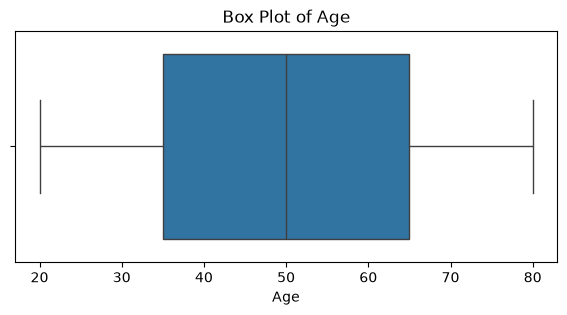

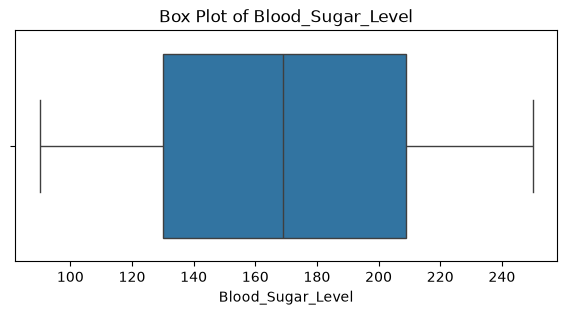

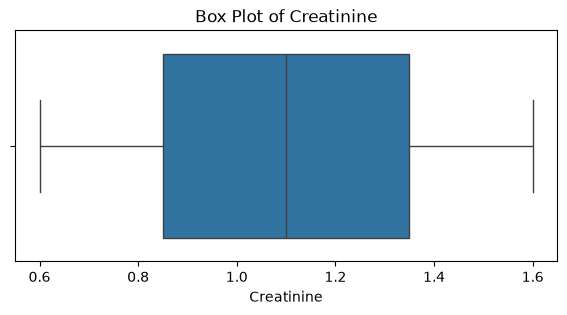

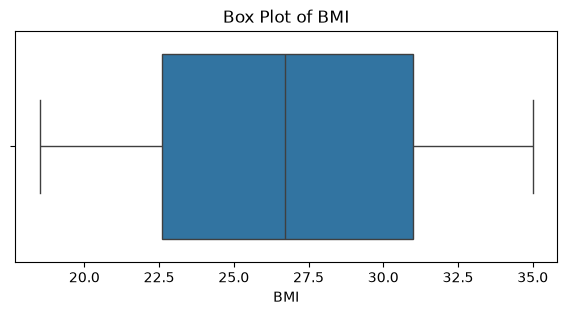

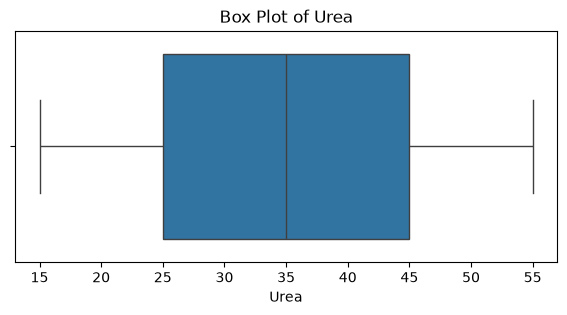

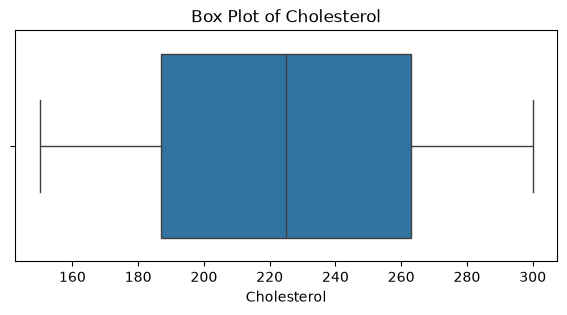

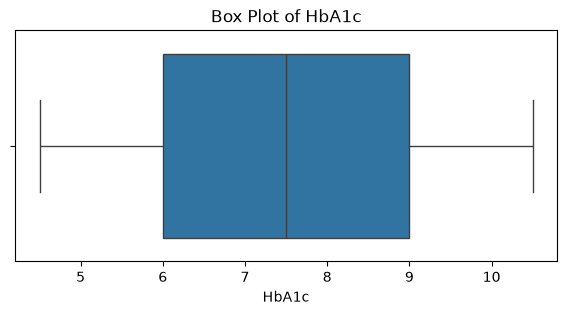

In [83]:

numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Box Plot of {col}')
    plt.show()

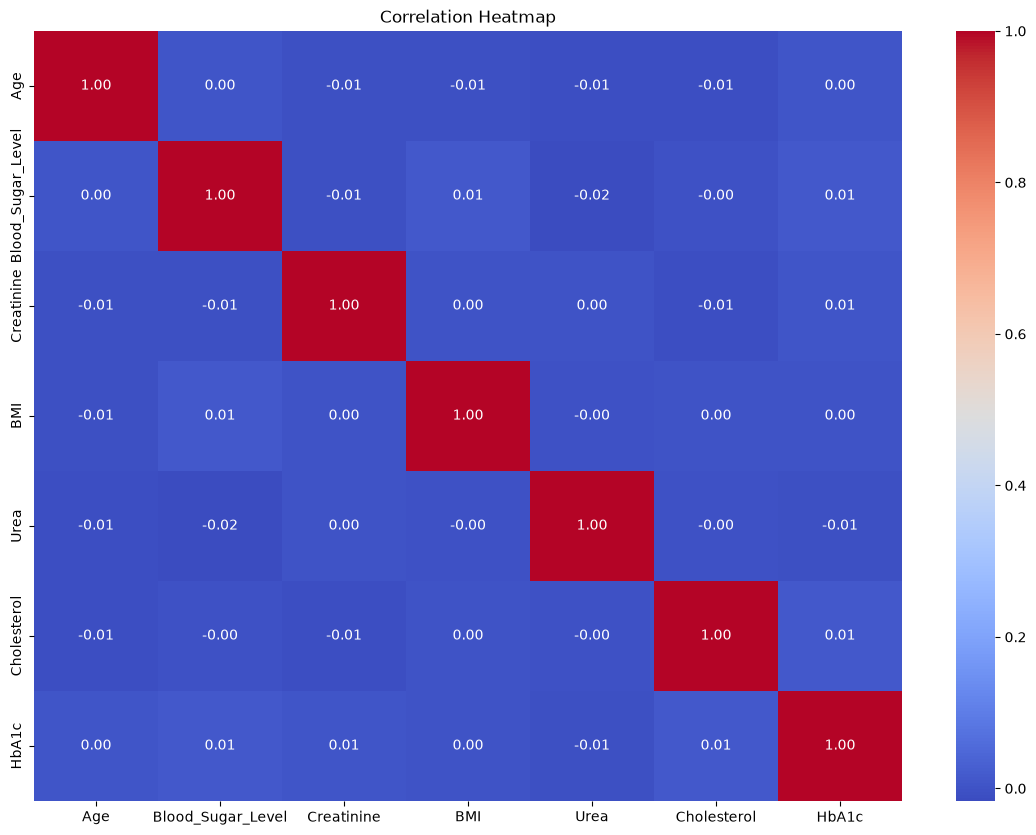

In [84]:

plt.figure(figsize=(14, 10))

corr = df.select_dtypes(include='number').corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()


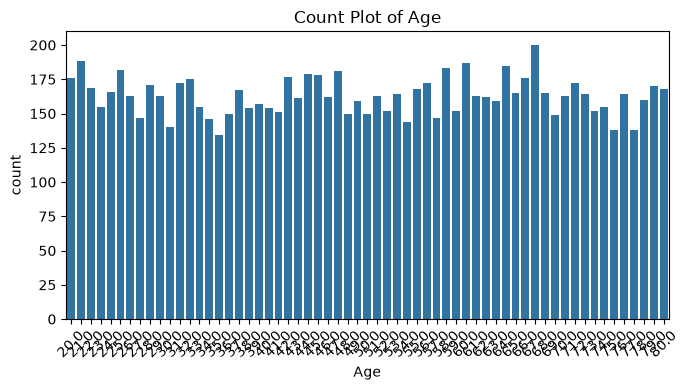

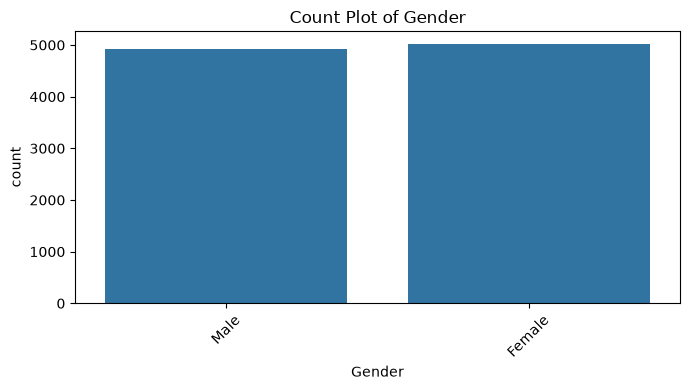

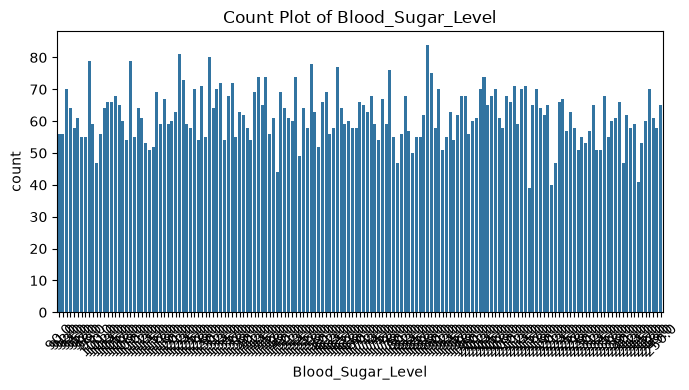

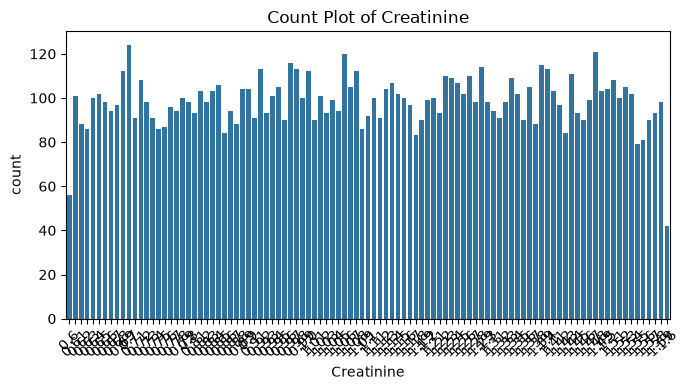

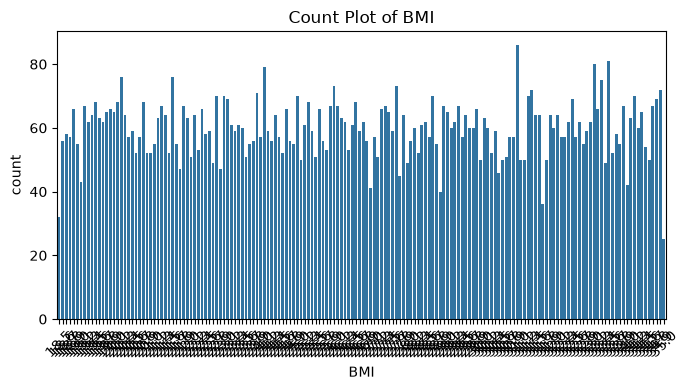

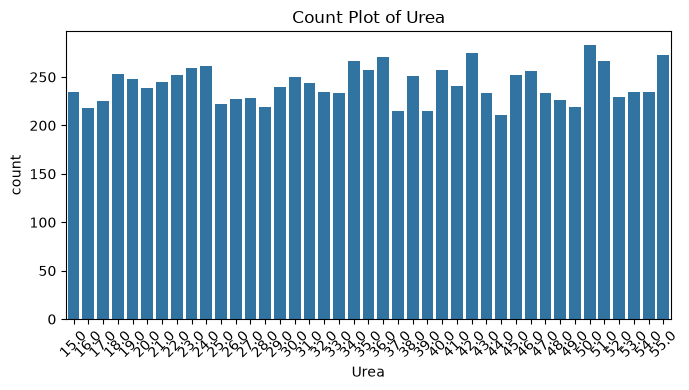

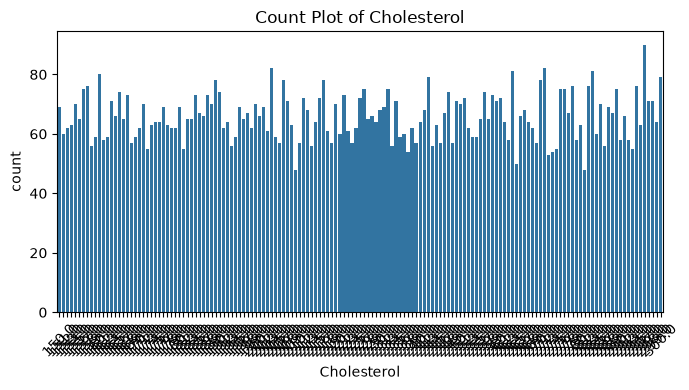

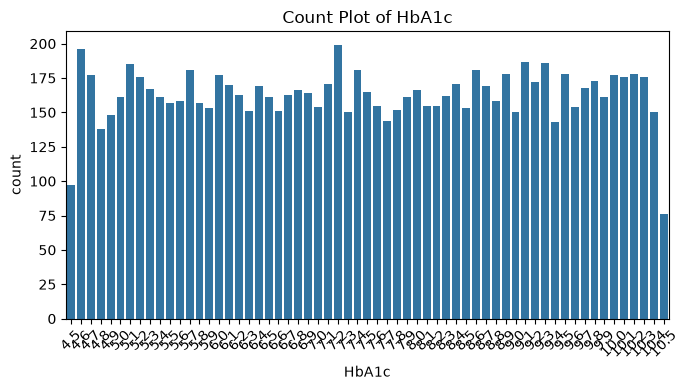

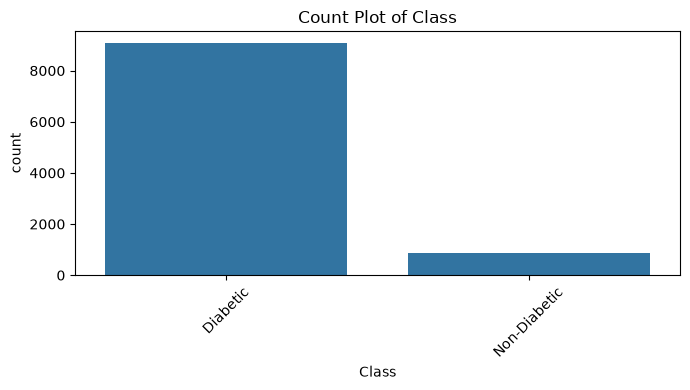

In [85]:

categorical_cols = df.columns
for col in categorical_cols:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=col)
    plt.title(f'Count Plot of {col}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


In [86]:
df = pd.get_dummies(df, columns=['Gender'], dtype=int)

In [87]:
df.head()

,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class,Gender_Female,Gender_Male
0,60.0,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic,0,1
1,77.0,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic,0,1
2,21.0,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic,0,1
3,30.0,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic,1,0
4,26.0,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic,1,0


In [88]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['Class'] = le.fit_transform(df['Class'])

In [89]:

from sklearn.model_selection import train_test_split
X = df.drop(columns=['Class'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)



In [90]:
df.describe()

,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class,Gender_Female,Gender_Male
count,9932.000000,9932.000000,9932.000000,9932.000000,9932.000000,9932.000000,9932.000000,9932.000000,9932.000000,9932.000000
mean,49.951269,169.241643,1.100316,26.748278,35.127467,225.325816,7.502638,0.085481,0.504833,0.495167
std,17.635345,46.066343,0.286962,4.788006,11.829405,43.793351,1.744035,0.279611,0.500002,0.500002
min,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000,0.000000,0.000000,0.000000
25%,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000,0.000000,0.000000,0.000000
50%,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000,0.000000,1.000000,0.000000
75%,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000,0.000000,1.000000,1.000000
max,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000,1.000000,1.000000,1.000000


In [91]:
df.dtypes

Age                  float64
Blood_Sugar_Level    float64
Creatinine           float64
BMI                  float64
Urea                 float64
Cholesterol          float64
HbA1c                float64
Class                  int64
Gender_Female          int64
Gender_Male            int64
dtype: object

In [92]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [93]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[1789   28]
 [  31  139]]


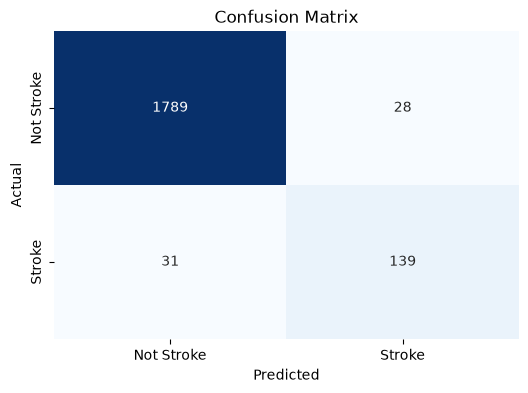


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.98      0.98      0.98      1817
      Stroke       0.83      0.82      0.82       170

    accuracy                           0.97      1987
   macro avg       0.91      0.90      0.90      1987
weighted avg       0.97      0.97      0.97      1987

ROC-AUC: 0.9901129852050892


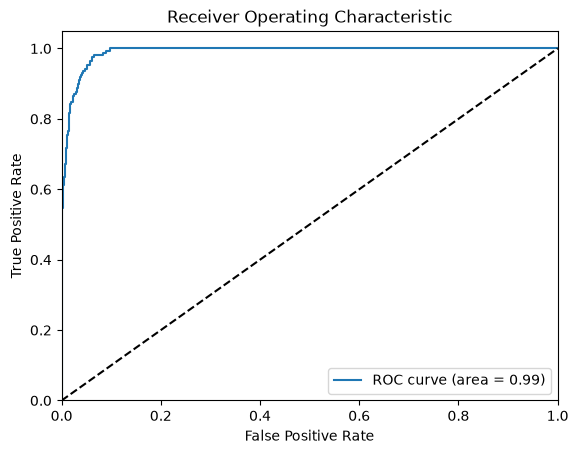

PR AUC: 0.9131026768162727


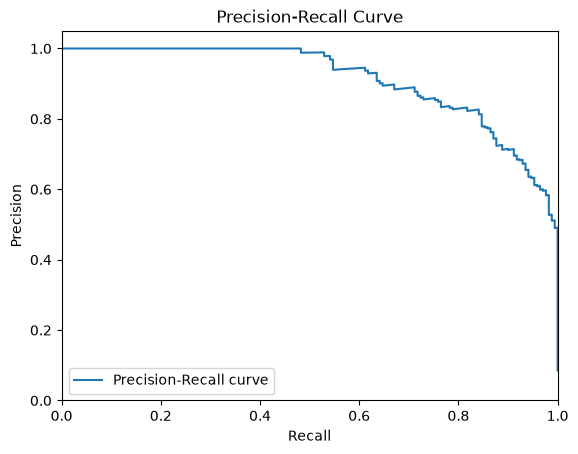

  8%|▊         | 1/13 [00:00<00:05,  2.01it/s]


Confusion Matrix:
 [[1778   39]
 [ 142   28]]


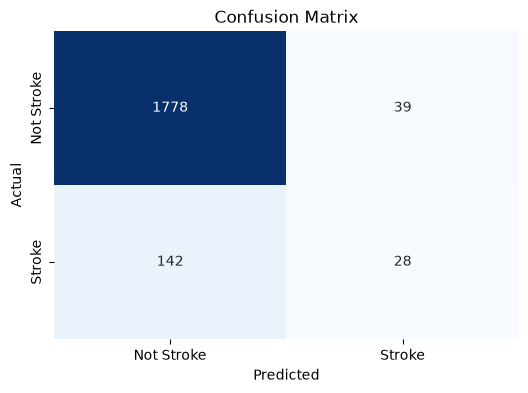


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.93      0.98      0.95      1817
      Stroke       0.42      0.16      0.24       170

    accuracy                           0.91      1987
   macro avg       0.67      0.57      0.59      1987
weighted avg       0.88      0.91      0.89      1987

ROC-AUC: 0.8294052899090292


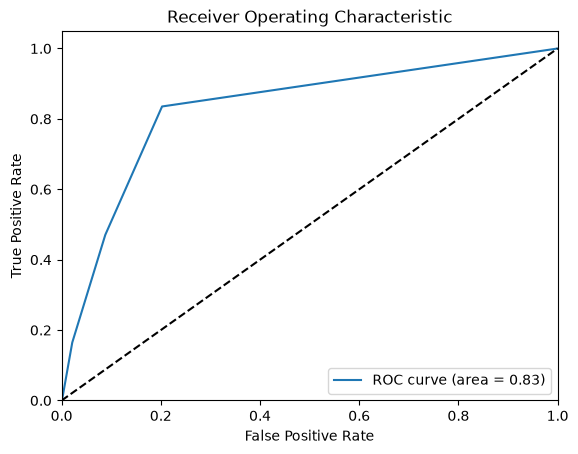

PR AUC: 0.2854352232512588


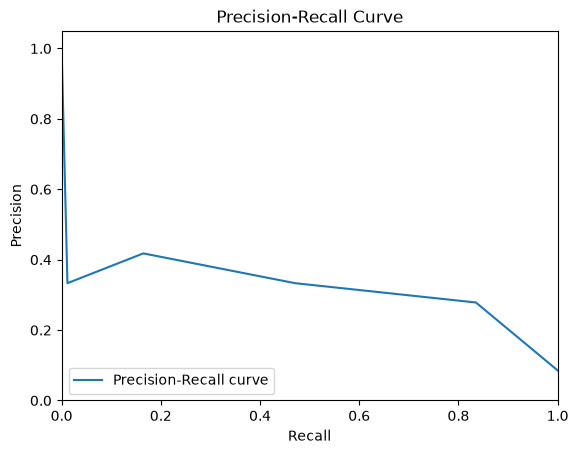

 15%|█▌        | 2/13 [00:00<00:04,  2.55it/s]c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Confusion Matrix:
 [[1817    0]
 [ 170    0]]


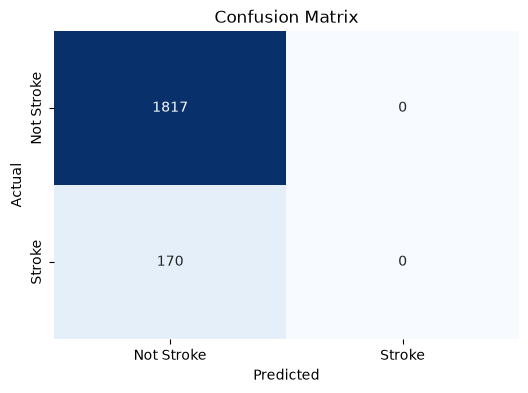


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.91      1.00      0.96      1817
      Stroke       0.00      0.00      0.00       170

    accuracy                           0.91      1987
   macro avg       0.46      0.50      0.48      1987
weighted avg       0.84      0.91      0.87      1987

ROC-AUC: 0.9928809608598531


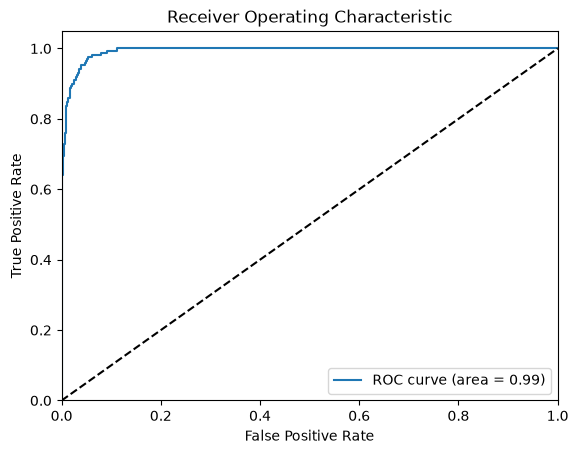

PR AUC: 0.9404424796068466


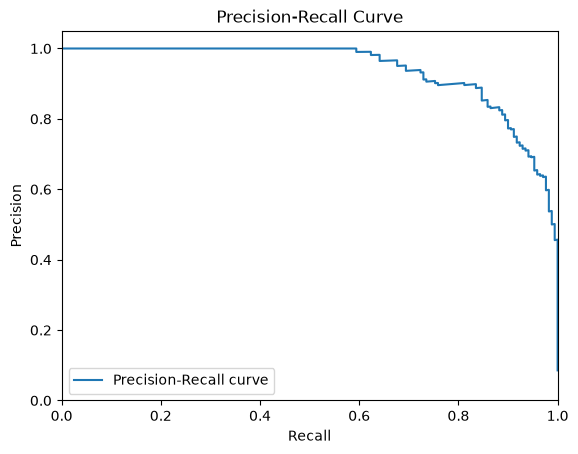

c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
 23%|██▎       | 3/13 [00:03<00:13,  1.37s/it]


Confusion Matrix:
 [[1817    0]
 [   0  170]]


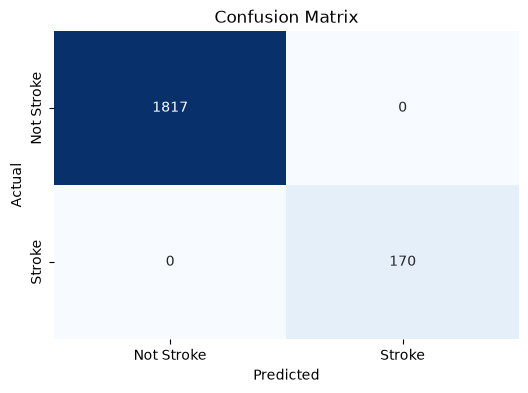


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


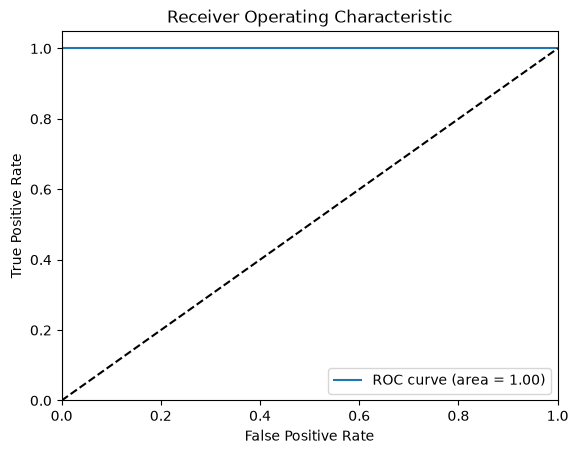

PR AUC: 1.0


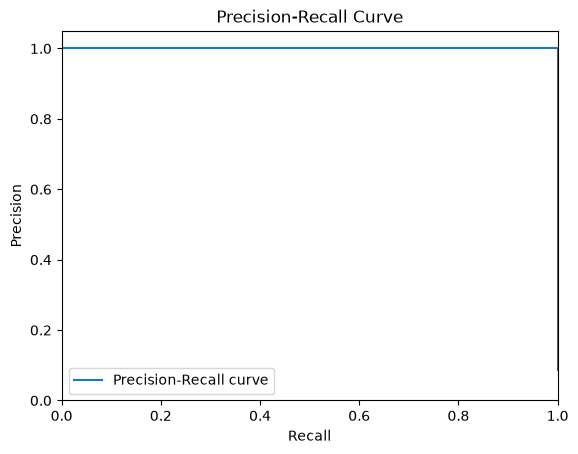

 31%|███       | 4/13 [00:03<00:08,  1.08it/s]


Confusion Matrix:
 [[1817    0]
 [  20  150]]


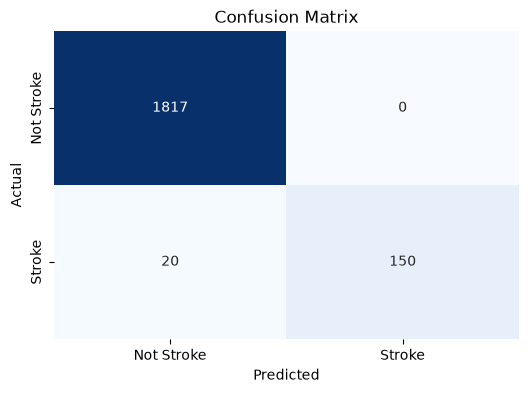


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      1.00      0.99      1817
      Stroke       1.00      0.88      0.94       170

    accuracy                           0.99      1987
   macro avg       0.99      0.94      0.97      1987
weighted avg       0.99      0.99      0.99      1987

ROC-AUC: 0.9992133121823303


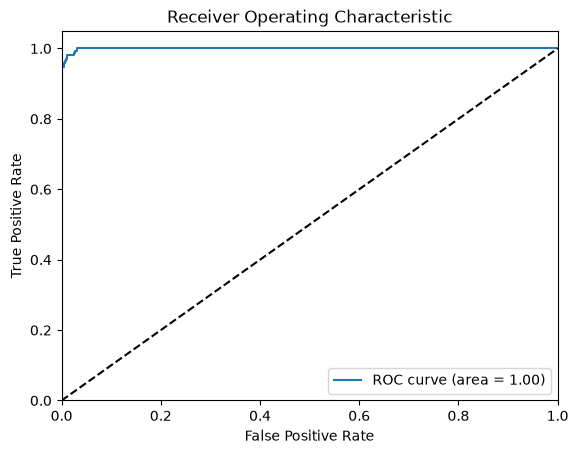

PR AUC: 0.9929167295194552


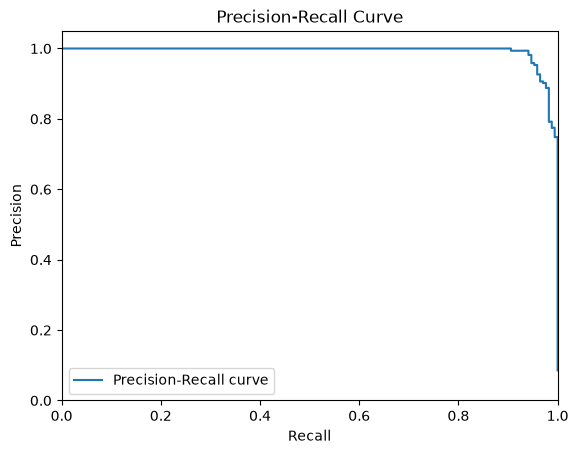

 38%|███▊      | 5/13 [00:03<00:05,  1.46it/s]


Confusion Matrix:
 [[1817    0]
 [   0  170]]


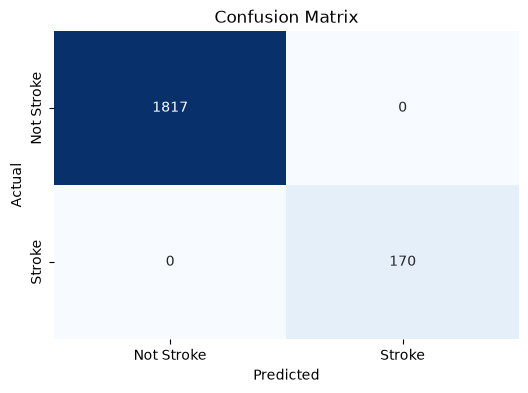


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


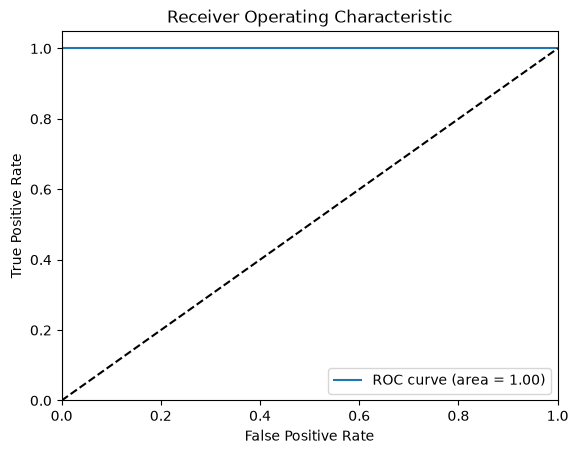

PR AUC: 1.0


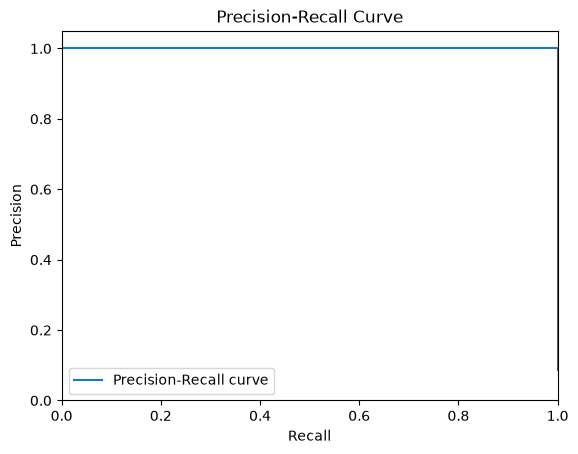

 46%|████▌     | 6/13 [00:04<00:04,  1.58it/s]


Confusion Matrix:
 [[1817    0]
 [   8  162]]


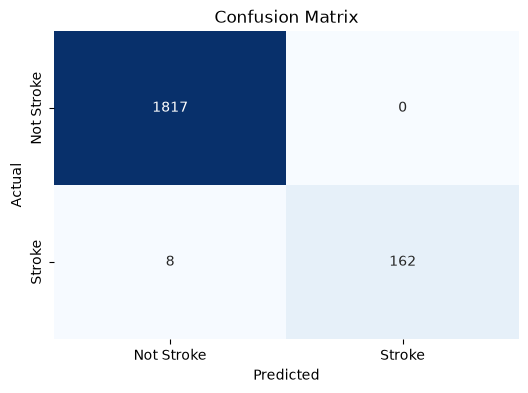


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      0.95      0.98       170

    accuracy                           1.00      1987
   macro avg       1.00      0.98      0.99      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 0.9997588138172164


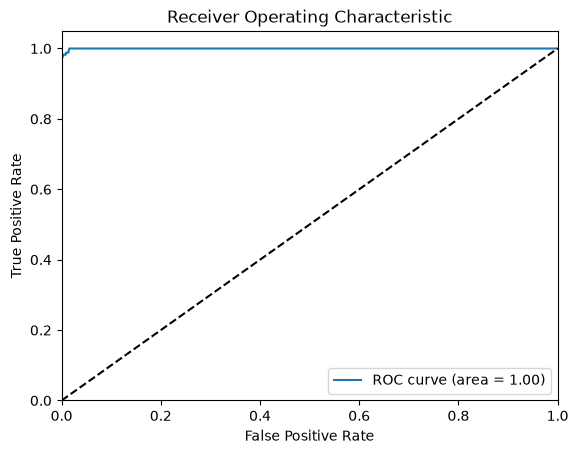

PR AUC: 0.9976313027892162


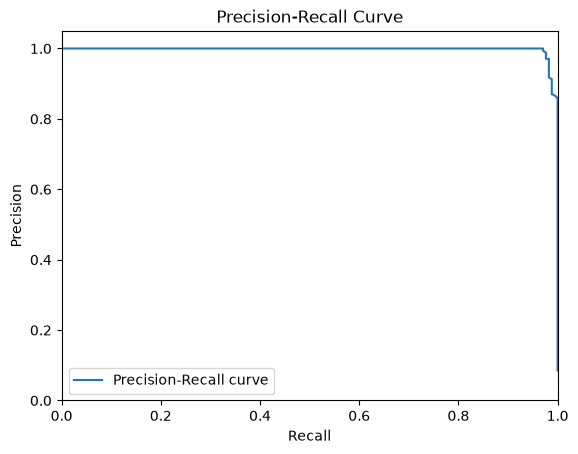

 54%|█████▍    | 7/13 [00:04<00:03,  1.64it/s]


Confusion Matrix:
 [[1817    0]
 [   0  170]]


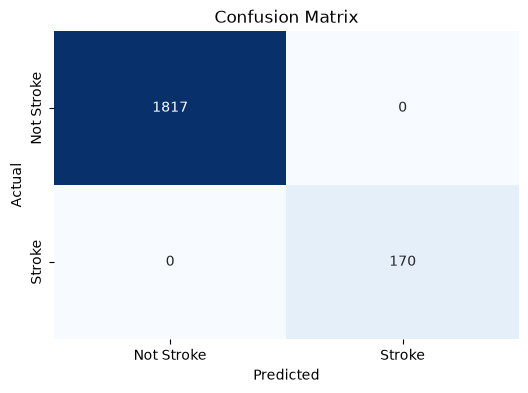


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


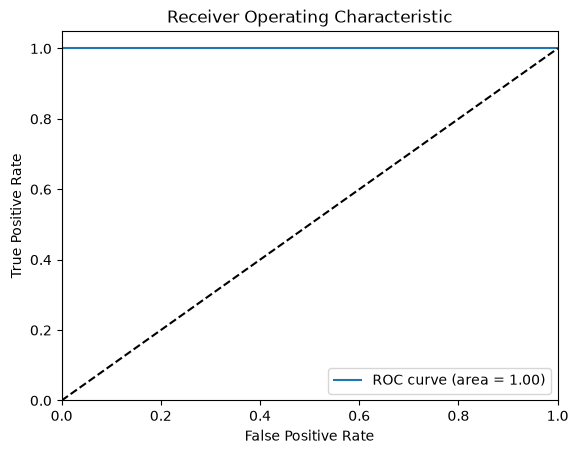

PR AUC: 1.0


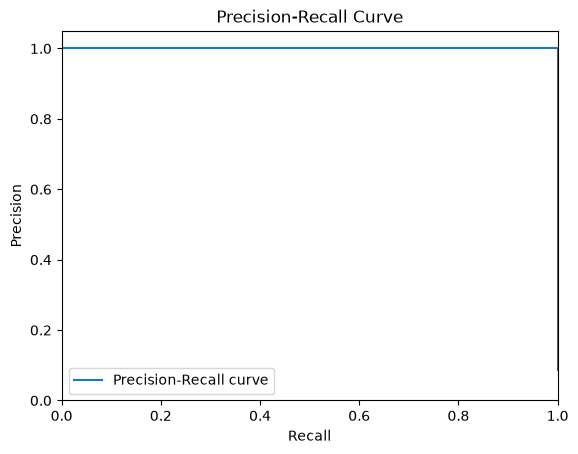

 62%|██████▏   | 8/13 [00:05<00:02,  1.77it/s]


Confusion Matrix:
 [[1817    0]
 [   0  170]]


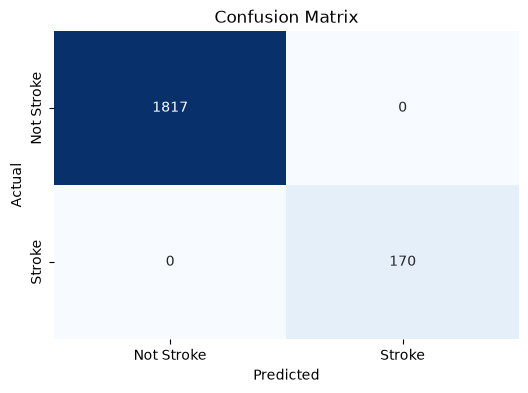


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


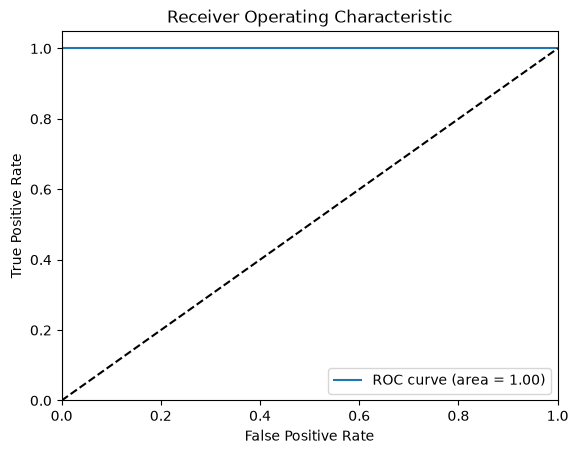

PR AUC: 1.0


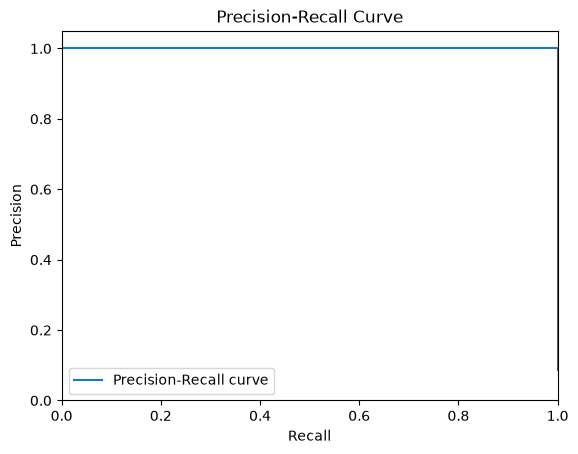

 69%|██████▉   | 9/13 [00:06<00:02,  1.69it/s]


Confusion Matrix:
 [[1817    0]
 [   0  170]]


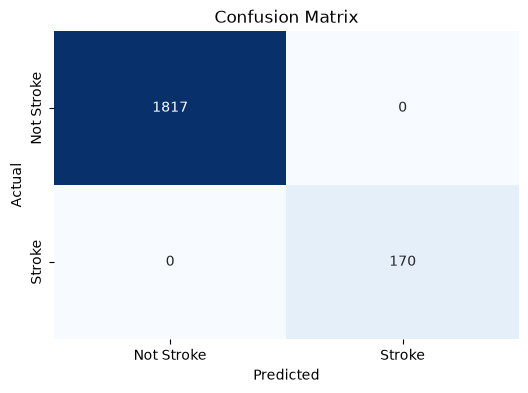


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


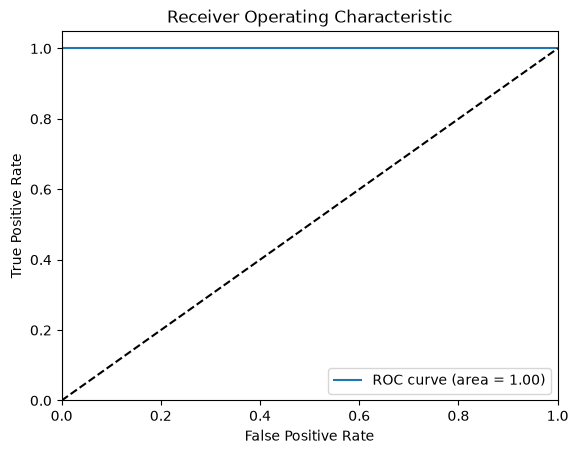

PR AUC: 1.0


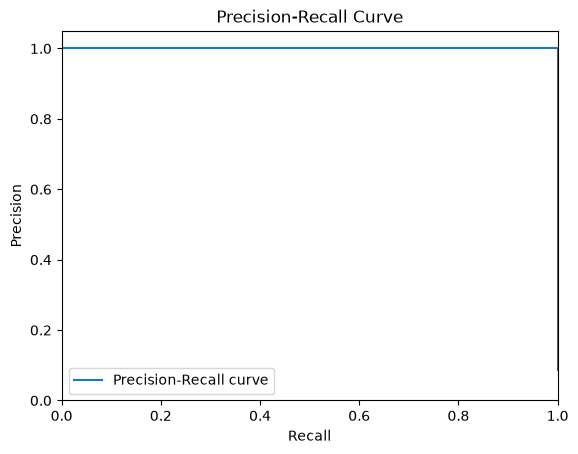

 77%|███████▋  | 10/13 [00:08<00:03,  1.17s/it]


Confusion Matrix:
 [[1817    0]
 [   0  170]]


c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [16:24:52] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


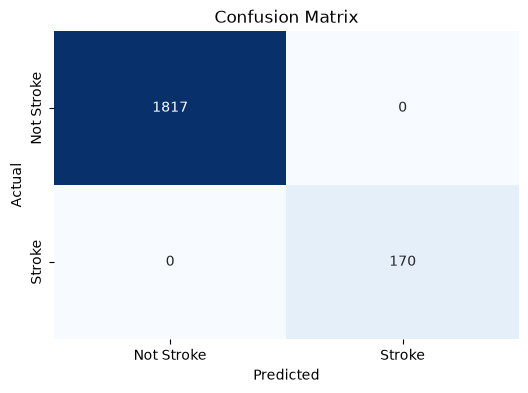


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


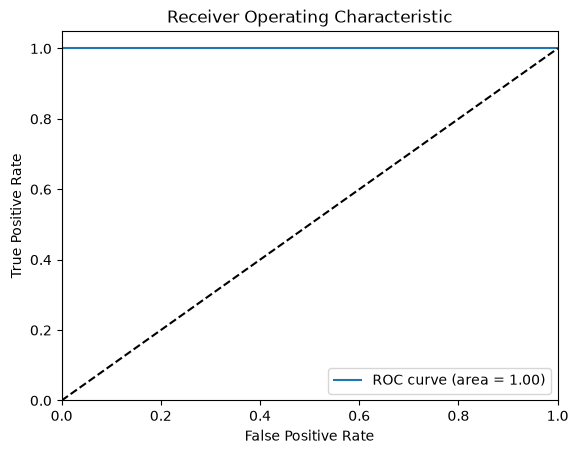

PR AUC: 1.0


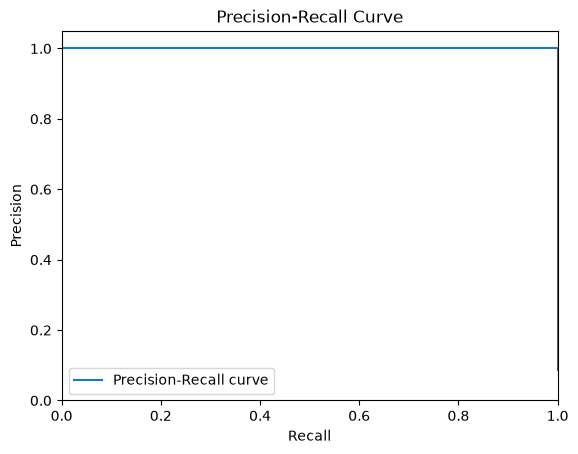

 85%|████████▍ | 11/13 [00:08<00:01,  1.07it/s]


Confusion Matrix:
 [[1817    0]
 [   0  170]]


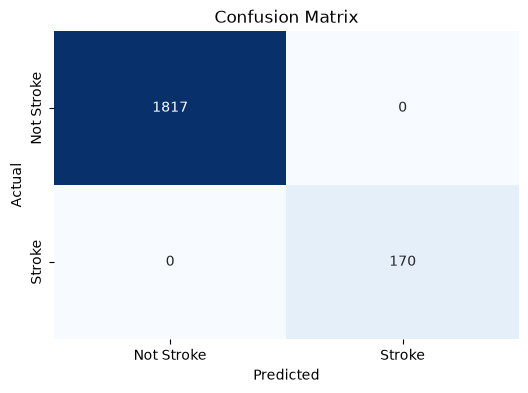


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


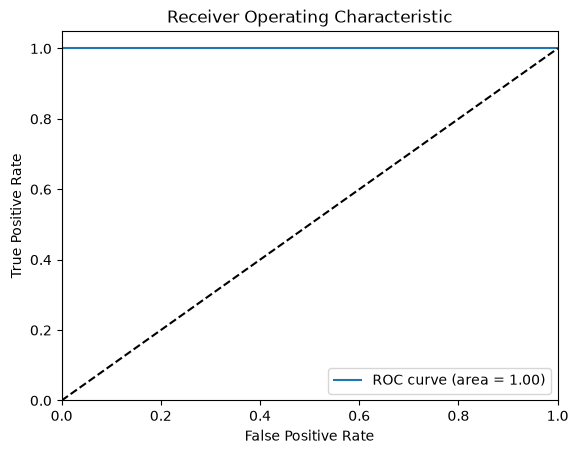

PR AUC: 0.9999999999999999


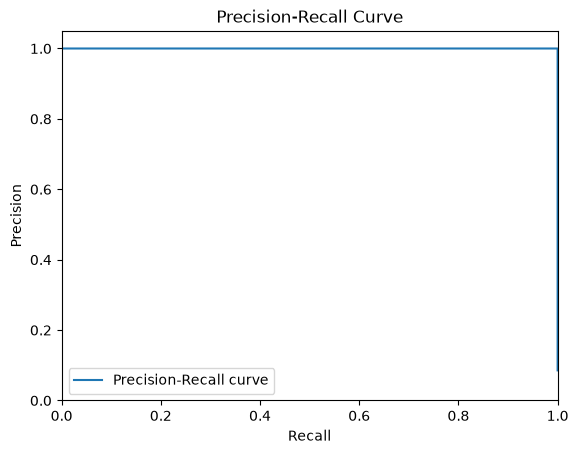

 92%|█████████▏| 12/13 [00:11<00:01,  1.54s/it]

[LightGBM] [Info] Number of positive: 679, number of negative: 7266
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000243 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 753
[LightGBM] [Info] Number of data points in the train set: 7945, number of used features: 9
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.085463 -> initscore=-2.370340
[LightGBM] [Info] Start training from score -2.370340
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, bes

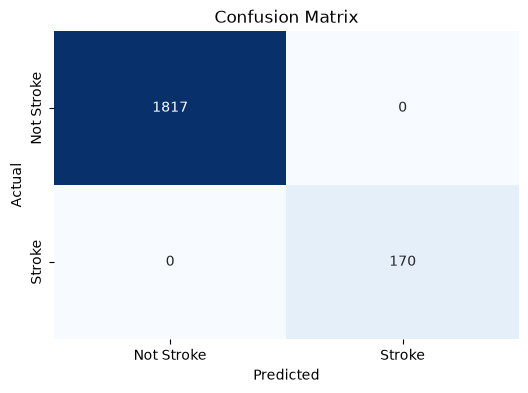


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


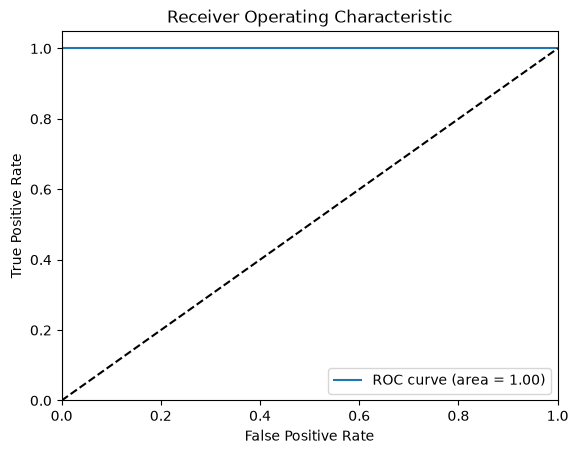

PR AUC: 1.0


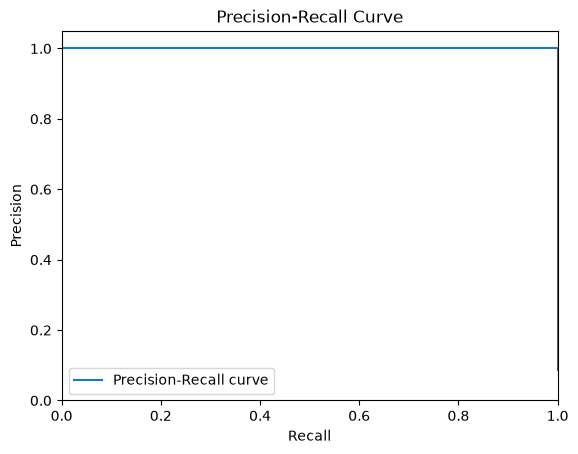

100%|██████████| 13/13 [00:12<00:00,  1.06it/s]


In [94]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)
    
    

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--') 
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    

In [103]:
results_df = pd.DataFrame(results).T
display(results_df)

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Logistic Regression,0.972687,0.970307,0.850000,0.832335,0.826215,0.817647,0.837939,0.824926,0.906295,0.901119,0.990113,0.913103
KNN,0.931026,0.908908,0.690962,0.417910,0.349043,0.164706,0.463796,0.236287,0.667227,0.571621,0.829405,0.285435
SVC,0.914537,0.914444,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.500000,0.992881,0.940442
Decision Tree,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Naive Bayes,0.991189,0.989935,1.000000,1.000000,0.896907,0.882353,0.945652,0.937500,0.948454,0.941176,0.999213,0.992917
Random Forest,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Extra Trees,1.000000,0.995974,1.000000,1.000000,1.000000,0.952941,1.000000,0.975904,1.000000,0.976471,0.999759,0.997631
AdaBoost,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Gradient Boosting,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Hist Gradient Boosting,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
